In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
from astropy.io import fits
from matplotlib import pyplot as plt

ROOT = Path.cwd()
FITS_DIR = ROOT / "fits_ready"
FIGS_DIR = ROOT / "Imgs"
FIGS_DIR.mkdir(exist_ok=True)


In [2]:
# -------------------------------------------------------
# MUSE 30 Doradus Halpha datasets
# -------------------------------------------------------

BINS = tuple(range(6))

DATASET_PREFIX = "MUSE-30Dor-H"
SUFFIX = "-ivsv"

datasets = [
    {
        "instrument": "MUSE",
        "bin": bin_level,
        "line": "Halpha",
        "filename": f"{DATASET_PREFIX}-bin{bin_level}{SUFFIX}.fits",
        "label": rf"${2**bin_level}\times{2**bin_level}$",
    }
    for bin_level in BINS
]

pd.DataFrame(datasets)


,instrument,bin,line,filename,label
0,MUSE,0,Halpha,MUSE-30Dor-H-bin0-ivsv.fits,$1\times1$
1,MUSE,1,Halpha,MUSE-30Dor-H-bin1-ivsv.fits,$2\times2$
2,MUSE,2,Halpha,MUSE-30Dor-H-bin2-ivsv.fits,$4\times4$
3,MUSE,3,Halpha,MUSE-30Dor-H-bin3-ivsv.fits,$8\times8$
4,MUSE,4,Halpha,MUSE-30Dor-H-bin4-ivsv.fits,$16\times16$
5,MUSE,5,Halpha,MUSE-30Dor-H-bin5-ivsv.fits,$32\times32$


In [3]:
def load_velocity_dataset(entry):
    fits_path = FITS_DIR / entry["filename"]

    if not fits_path.exists():
        raise FileNotFoundError(f"Missing FITS file: {fits_path}")

    with fits.open(fits_path) as hdul:
        sb = hdul["MOM0"].data.astype(float)
        vv = hdul["MOM1"].data.astype(float)

    yy, xx = np.indices(vv.shape)

    df = pd.DataFrame({
        "X": xx.ravel(),
        "Y": yy.ravel(),
        "VV": vv.ravel(),
        "SB": sb.ravel(),
    })

    df = df.dropna(subset=["VV", "SB"])

    df["instrument"] = entry["instrument"]
    df["line"] = entry["line"]
    df["label"] = entry["label"]
    df["filename"] = entry["filename"]
    df["bin"] = entry["bin"]

    mean_v = df["VV"].mean()
    df["RV_centered"] = df["VV"] - mean_v

    raw = {
        "sb": sb,
        "vv": vv,
        "instrument": entry["instrument"],
        "line": entry["line"],
        "label": entry["label"],
        "filename": entry["filename"],
        "bin": entry["bin"],
    }

    return df, raw


In [4]:
processed_list = []
raw_data = {}

for entry in datasets:
    df, raw = load_velocity_dataset(entry)
    processed_list.append(df)

    key = (entry["line"], entry["instrument"], entry["bin"])
    raw_data[key] = raw

processed_data = pd.concat(processed_list, ignore_index=True)

print(f"Loaded {len(datasets)} MUSE 30 Doradus Halpha datasets")


Loaded 6 MUSE 30 Doradus Halpha datasets


In [5]:
processed_data.head()

,X,Y,VV,SB,instrument,line,label,filename,bin,RV_centered
0,14,0,303.576356,0.039065,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,35.629709
1,15,0,303.905085,0.038140,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,35.958438
2,16,0,300.934901,0.036980,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,32.988253
3,17,0,299.151888,0.037957,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,31.205241
4,18,0,297.229469,0.038110,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,29.282822


In [6]:
processed_data.groupby("bin")[["VV", "RV_centered", "SB"]].describe()


VV                                                              \
        count        mean         std         min         25%         50%   
bin                                                                         
0    241086.0  267.946647   16.711979   91.565124  256.508678  267.250809   
1     60099.0  267.918955   16.606629  219.884477  256.599891  267.134443   
2     14964.0  268.592611   22.276969  223.776876  256.645753  267.119944   
3      3706.0  270.054679   36.923826  226.244757  257.010626  267.358746   
4       913.0  271.636472   72.743384  227.019321  257.473537  267.417692   
5       215.0  291.689800  350.551330  230.857426  258.815896  266.675743   

                             RV_centered                ...             \
            75%          max       count          mean  ...        75%   
bin                                                     ...              
0    279.478861   610.812809    241086.0  9.053978e-17  ...  11.532214   
1    279.338122   334.170556     60099.0  6.987033e-14  ...  11.419166   
2    279.332791  1138.166682     14964.0 -2.820139e-14  ...  10.740180   
3    279.567470  1263.420446      3706.0 -4.417405e-15  ...   9.512791   
4    279.551673  2107.463687       913.0  7.471205e-15  ...   7.915201   
5    279.050665  5402.259530       215.0 -2.115104e-14  ... -12.639135   

                        SB                                                    \
             max     count      mean       std       min       25%       50%   
bin                                                                            
0     342.866162  241086.0  0.104253  0.104303  0.000054  0.030389  0.070353   
1      66.251601   60099.0  0.106496  0.106381  0.002012  0.031160  0.071899   
2     869.574072   14964.0  0.109111  0.108702  0.001891  0.032248  0.073665   
3     993.365767    3706.0  0.119088  0.117371  0.001065  0.035698  0.081600   
4    1835.827215     913.0  0.144661  0.139880  0.002522  0.043804  0.099446   
5    5110.569730     215.0  0.198470  0.181877  0.006973  0.070552  0.142000   

                    
          75%  max  
bin                 
0    0.143010  1.0  
1    0.146202  1.0  
2    0.149643  1.0  
3    0.164808  1.0  
4    0.198567  1.0  
5    0.279922  1.0  

[6 rows x 24 columns]

In [7]:
processed_data

,X,Y,VV,SB,instrument,line,label,filename,bin,RV_centered
0,14,0,303.576356,0.039065,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,35.629709
1,15,0,303.905085,0.038140,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,35.958438
2,16,0,300.934901,0.036980,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,32.988253
3,17,0,299.151888,0.037957,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,31.205241
4,18,0,297.229469,0.038110,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,29.282822
...,...,...,...,...,...,...,...,...,...,...
320978,1,15,339.382105,0.252871,MUSE,Halpha,$32\times32$,MUSE-30Dor-H-bin5-ivsv.fits,5,47.692305
320979,2,15,307.742857,0.527128,MUSE,Halpha,$32\times32$,MUSE-30Dor-H-bin5-ivsv.fits,5,16.053056
320980,7,15,274.555510,0.554451,MUSE,Halpha,$32\times32$,MUSE-30Dor-H-bin5-ivsv.fits,5,-17.134291
320981,14,15,277.237866,0.339437,MUSE,Halpha,$32\times32$,MUSE-30Dor-H-bin5-ivsv.fits,5,-14.451934


In [8]:
# Convenient dictionary: one DataFrame per bin level
ha_muse = {
    bin_level: processed_data[
        processed_data["bin"] == bin_level
    ].copy()
    for bin_level in BINS
}

# Optional aliases, kept for compatibility with the original notebook
ha_muse_bin0 = ha_muse[0]
ha_muse_bin1 = ha_muse[1]
ha_muse_bin2 = ha_muse[2]
ha_muse_bin3 = ha_muse[3]
ha_muse_bin4 = ha_muse[4]
ha_muse_bin5 = ha_muse[5]


In [9]:
instrument_colors = {
    "MUSE": "black",
}

line_order = ["Halpha"]


## Surface brightness vs radial velocity

The following panels compare the complete H\(\alpha\) intensity–velocity distribution across spatial binning levels.


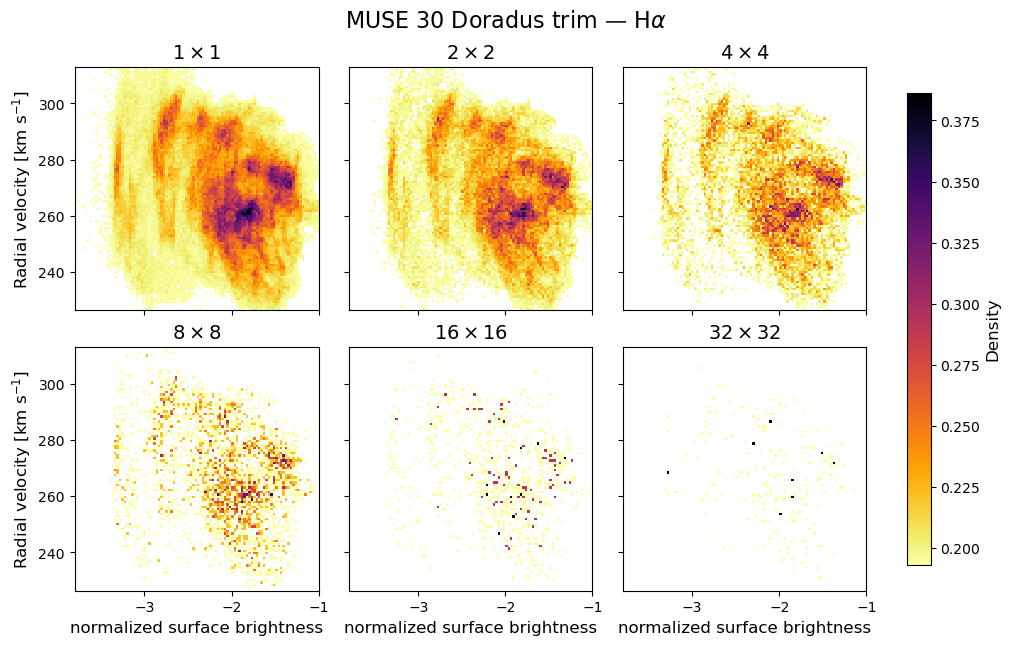

In [13]:
datasets_by_bin = ha_muse

bin_labels = {
    bin_level: rf"${2**bin_level}\times{2**bin_level}$"
    for bin_level in BINS
}

bin_order = list(BINS)

# Surface-brightness range is kept from the original diagnostic.
xrange = [-3.8, -1.0]

# Use one common radial-velocity range for all panels, derived from the
# complete 30 Dor sample. This avoids Orion-specific hard-coded limits.
v_lo, v_hi = np.nanpercentile(processed_data["VV"], [0.5, 99.5])
ypad = 0.05 * (v_hi - v_lo)
yrange = [v_lo - ypad, v_hi + ypad]

nbins_hist = 100

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()
im = None

for ax, bin_id in zip(axes, bin_order):

    data = datasets_by_bin[bin_id]

    SB = np.asarray(data["SB"])
    VV = np.asarray(data["VV"])

    mask = (
        np.isfinite(SB)
        & np.isfinite(VV)
        & (SB > 0)
    )

    SB_valid = SB[mask]
    VV_valid = VV[mask]

    # Same normalization convention as the original notebook.
    SB_norm = SB_valid / (np.nanmedian(SB_valid) * 100)

    x = np.log10(SB_norm)
    y = VV_valid

    H, xedges, yedges = np.histogram2d(
        x,
        y,
        bins=nbins_hist,
        range=[xrange, yrange],
        density=True,
    )

    HH = np.where(H == 0, np.nan, H)

    im = ax.imshow(
        HH.T,
        origin="lower",
        aspect="auto",
        cmap="inferno_r",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        interpolation="nearest",
    )

    ax.set_title(bin_labels[bin_id], fontsize=14)
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.grid(False)

for idx, ax in enumerate(axes):
    row = idx // 3
    col = idx % 3

    if col == 0:
        ax.set_ylabel(
            r"Radial velocity [km s$^{-1}$]",
            fontsize=12,
        )

    if row == 1:
        ax.set_xlabel(
            r"normalized surface brightness",
            fontsize=12,
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.9,
    pad=0.03,
)

fig.suptitle(
    r"MUSE 30 Doradus trim — H$\alpha$",
    fontsize=16,
    y=1.05,
)

cbar.set_label("Density", fontsize=12)

fig.savefig(
    FIGS_DIR / "MUSE_sb_vs_vv_bins_trim.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.show()


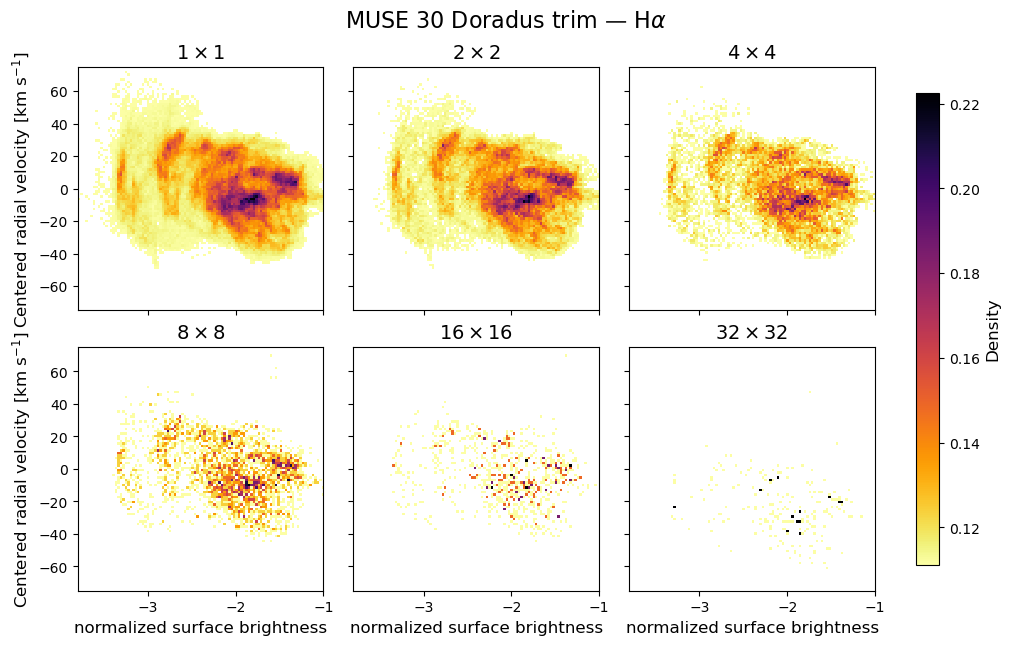

In [12]:
datasets_by_bin = ha_muse

bin_labels = {
    bin_level: rf"${2**bin_level}\times{2**bin_level}$"
    for bin_level in BINS
}

bin_order = list(BINS)

xrange = [-3.8, -1.0]

# Common centered-velocity range for all panels.
rv_lo, rv_hi = np.nanpercentile(processed_data["RV_centered"], [0.5, 99.5])
rv_span = max(abs(rv_lo), abs(rv_hi))
yrange = [-75, 75]

nbins_hist = 100

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()
im = None

for ax, bin_id in zip(axes, bin_order):

    data = datasets_by_bin[bin_id]

    SB = np.asarray(data["SB"])
    RV = np.asarray(data["RV_centered"])

    mask = (
        np.isfinite(SB)
        & np.isfinite(RV)
        & (SB > 0)
    )

    SB_valid = SB[mask]
    RV_valid = RV[mask]

    SB_norm = SB_valid / (np.nanmedian(SB_valid) * 100)

    x = np.log10(SB_norm)
    y = RV_valid

    H, xedges, yedges = np.histogram2d(
        x,
        y,
        bins=nbins_hist,
        range=[xrange, yrange],
        density=True,
    )

    HH = np.where(H == 0, np.nan, H)

    im = ax.imshow(
        HH.T,
        origin="lower",
        aspect="auto",
        cmap="inferno_r",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        interpolation="nearest",
    )

    ax.set_title(bin_labels[bin_id], fontsize=14)
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.grid(False)

for idx, ax in enumerate(axes):
    row = idx // 3
    col = idx % 3

    if col == 0:
        ax.set_ylabel(
            r"Centered radial velocity [km s$^{-1}$]",
            fontsize=12,
        )

    if row == 1:
        ax.set_xlabel(
            r"normalized surface brightness",
            fontsize=12,
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.9,
    pad=0.03,
)

fig.suptitle(
    r"MUSE 30 Doradus trim — H$\alpha$",
    fontsize=16,
    y=1.05,
)

cbar.set_label("Density", fontsize=12)

fig.savefig(
    FIGS_DIR / "MUSE_sb_vs_centered_vv_bins_trim.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.show()
